# AgriPredict — Modélisation : from scratch vs scikit-learn

Ce notebook démontre l'implémentation **from scratch en NumPy** d'une régression
linéaire entraînée par descente de gradient (cf. Machine Learning Specialization,
Andrew Ng — Cours 1, semaines 1 à 3), puis la compare aux modèles scikit-learn
utilisés pour la version déployée du projet.

Rappel des formules implémentées dans `src/scratch_ml.py` :

$$\hat{y} = X\theta \qquad
J(\theta) = \frac{1}{2m}\sum_{i=1}^m (\hat{y}_i - y_i)^2 + \frac{\lambda}{2m}\sum_{j\neq 0}\theta_j^2 \qquad
\theta := \theta - \alpha \frac{\partial J}{\partial \theta}$$

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.common import load_dataset, temporal_split, NUM, CAT, TARGET
from src.scratch_ml import LinearRegressionScratch, mse_scratch, r2_scratch

df = load_dataset("../data/processed/dataset.csv")
train, test = temporal_split(df, n_test_years=5)
print(f"{len(train)} lignes train / {len(test)} lignes test")

90 lignes train / 15 lignes test


## 1. Entraînement du modèle from scratch

In [2]:
model = LinearRegressionScratch(
    num_features=NUM, cat_feature=CAT[0],
    learning_rate=0.3, n_iterations=5000, lambda_reg=0.0,
)
model.fit(train, TARGET)

pred = model.predict(test[NUM + CAT])
rmse = np.sqrt(mse_scratch(test[TARGET].to_numpy(), pred))
r2 = r2_scratch(test[TARGET].to_numpy(), pred)
print(f"RMSE = {rmse:.4f}   R2 = {r2:.4f}")

RMSE = 1.0319   R2 = 0.9690


## 2. Convergence de la descente de gradient

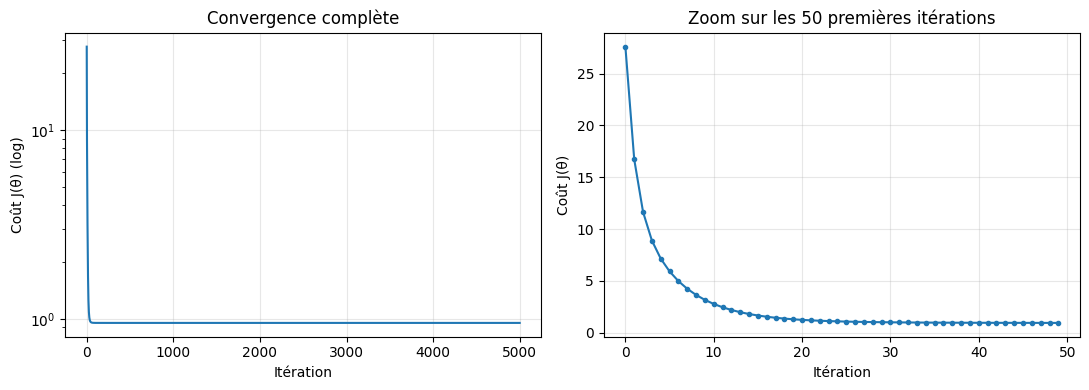

Coût initial : 27.5971  ->  Coût final : 0.9511


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(model.cost_history_)
axes[0].set_yscale("log")
axes[0].set_xlabel("Itération"); axes[0].set_ylabel("Coût J(θ) (log)")
axes[0].set_title("Convergence complète"); axes[0].grid(alpha=0.3)

n_zoom = 50
axes[1].plot(range(n_zoom), model.cost_history_[:n_zoom], marker="o", markersize=3)
axes[1].set_xlabel("Itération"); axes[1].set_ylabel("Coût J(θ)")
axes[1].set_title(f"Zoom sur les {n_zoom} premières itérations"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Coût initial : {model.cost_history_[0]:.4f}  ->  Coût final : {model.cost_history_[-1]:.4f}")

**Lecture** : le coût chute très rapidement (moins de 30 itérations) car le
dataset est petit et les variables sont standardisées — la surface de coût est
bien conditionnée. Un taux d'apprentissage trop élevé ferait diverger le coût
(à tester : `learning_rate=3.0` ci-dessous, pédagogique uniquement).

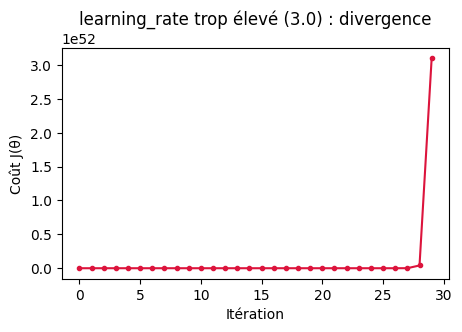

Coût : [np.float64(27.59709207038889), np.float64(117.37965822729112), np.float64(1067.5261181672743), np.float64(12646.11088122711), np.float64(354816.23096305516)] ...


In [4]:
# Démonstration : un taux d'apprentissage trop élevé fait diverger la descente
model_diverge = LinearRegressionScratch(NUM, CAT[0], learning_rate=3.0, n_iterations=30, lambda_reg=0.0)
model_diverge.fit(train, TARGET)
plt.figure(figsize=(5, 3))
plt.plot(model_diverge.cost_history_, marker="o", markersize=3, color="crimson")
plt.title("learning_rate trop élevé (3.0) : divergence")
plt.xlabel("Itération"); plt.ylabel("Coût J(θ)")
plt.show()
print("Coût :", model_diverge.cost_history_[:5], "...")

## 3. Vérification : from scratch vs scikit-learn

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pre = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(), CAT)])
pipe_sklearn = Pipeline([("pre", pre), ("model", LinearRegression())]).fit(train[NUM + CAT], train[TARGET])
pred_sklearn = pipe_sklearn.predict(test[NUM + CAT])

max_diff = np.max(np.abs(pred - pred_sklearn))
print(f"Écart maximal entre les prédictions from-scratch et scikit-learn : {max_diff:.2e}")
print("(proche de 0 => la descente de gradient converge vers le même optimum que la solution scikit-learn)")

Écart maximal entre les prédictions from-scratch et scikit-learn : 1.11e-14
(proche de 0 => la descente de gradient converge vers le même optimum que la solution scikit-learn)


## 4. Effet de la régularisation L2

On teste plusieurs valeurs de $\lambda$ pour voir si pénaliser les grands
coefficients améliore la généralisation sur les années de test.

In [6]:
rows = []
for lam in [0.0, 1.0, 5.0, 10.0, 50.0]:
    m = LinearRegressionScratch(NUM, CAT[0], learning_rate=0.3, n_iterations=5000, lambda_reg=lam).fit(train, TARGET)
    p = m.predict(test[NUM + CAT])
    rows.append({"lambda": lam,
                 "rmse": np.sqrt(mse_scratch(test[TARGET].to_numpy(), p)),
                 "r2": r2_scratch(test[TARGET].to_numpy(), p)})
pd.DataFrame(rows)

,lambda,rmse,r2
0,0.0,1.031885,0.969015
1,1.0,1.094103,0.965166
2,5.0,1.477440,0.936481
3,10.0,1.959921,0.888221
4,50.0,3.809300,0.577745


**Interprétation** : sur ce petit dataset (90 lignes d'entraînement, 5 variables),
la régularisation L2 dégrade les performances de test au lieu de les améliorer.
Ce n'est pas surprenant : la régularisation lutte contre le sur-apprentissage,
qui n'est pas le problème principal ici (peu de variables, pas de sur-paramétrage).
On garde donc $\lambda = 0$ pour la version from-scratch du projet.

## 5. Comparaison avec les modèles non linéaires (scikit-learn)

In [7]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone

models_sklearn = {
    "random_forest": RandomForestRegressor(n_estimators=300, max_depth=6, random_state=42),
    "gradient_boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42),
}

def make_pipe(m):
    return Pipeline([("pre", pre), ("model", clone(m))])

rows = [{"modele": "linear_scratch (NumPy)", "rmse": rmse, "r2": r2}]
rows.append({"modele": "linear (sklearn)",
             "rmse": np.sqrt(mse_scratch(test[TARGET].to_numpy(), pred_sklearn)),
             "r2": r2_scratch(test[TARGET].to_numpy(), pred_sklearn)})
for name, m in models_sklearn.items():
    p = make_pipe(m).fit(train[NUM + CAT], train[TARGET]).predict(test[NUM + CAT])
    rows.append({"modele": name,
                 "rmse": np.sqrt(mse_scratch(test[TARGET].to_numpy(), p)),
                 "r2": r2_scratch(test[TARGET].to_numpy(), p)})

pd.DataFrame(rows).set_index("modele")

,rmse,r2
modele,,
linear_scratch (NumPy),1.031885,0.969015
linear (sklearn),1.031885,0.969015
random_forest,0.554181,0.991063
gradient_boosting,0.634586,0.988282


**Conclusion** : le modèle from-scratch valide la compréhension mathématique
(coût, gradient, convergence, régularisation) et retrouve exactement les
performances d'une régression linéaire scikit-learn. Mais comme les relations
entre climat/intrants et rendement ne sont pas purement linéaires (voir EDA),
les modèles non linéaires (Random Forest, Gradient Boosting) restent
nécessaires pour la meilleure performance en déploiement — c'est pour cela que
le projet garde les deux approches, avec des rôles différents et complémentaires.